# residual_flags

**Question.** Can physics-free, residual-based detection replace oracle flags? A faulty reading should disagree with
the field the model predicts at that probe's own location: flag probes with a large residual, then feed the flags
into the existing mask. Test time only: the `random_readings` checkpoints (`robust_shred_v1__missing` and
`shred_mask__missing`, trained on `missing` with oracle flags; `robust_shred_v1__garbage` ("v1-garbage"), trained on
unflagged garbage, so it never saw a mask; all MPS) plus one new checkpoint from `residual_flags_train`: v1 trained on
garbage (p = 0.3) where each faulty probe is flagged with probability 0.5 ("v1-mixed", `flag_frac: 0.5`, MPS, 3 seeds),
so it learns both to use flags and to cope with unflagged garbage, with the same splits, masks, noise and
garbage draws as that experiment.

Setup (`configs/experiment/residual_flags.yaml`, code `src/get_shredded/residual_flags.py`):
- **Pass 1:** the model with no flags (all probes in). Residual r = last-lag reading − prediction at the probe's
  grid point, in physical units, per channel.
- **Score:** d_j = sqrt((r_u/s_u)² + (r_v/s_v)²), with s = residual std on clean validation windows (fixed
  validation noise, no faults).
- **Hard flags:** flag probe j for the whole window if d_j > τ_j, where τ_j = quantile q of d_j on that validation
  set. The mask is per window per probe, and the faults are whole-window (unchanged from `random_readings`), so the
  last lag is the only residual a window has.
- **Soft (v1 only):** add log(max(w, 1e-6)), with w = exp(−0.5 d²), to v1's probe-attention logits at every lag;
  the null token is unbiased.
- **Pass 2:** the same model with those flags.

Conditions: garbage, exactly k of 8 probes faulty (k = 0 = noise only, the false-alarm check), 10 draws per test
window, plus noise-free `clean`. Error = relative L2 over the test snapshots (`err`, as in `experiments/LOG.md`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from get_shredded.runner import PROJECT_ROOT

NAME = "residual_flags"   # full run, 3 seeds ("residual_flags_smoke" = seed-0 smoke)
ROOT = PROJECT_ROOT / "outputs" / NAME / "nektar_uv"
SOURCE = PROJECT_ROOT / "outputs" / "random_readings" / "nektar_uv"
summary = json.loads((ROOT / "summary.json").read_text())
SEEDS = summary["seeds"]
KS = list(range(8))
LABELS = {
    "shred_mask__missing__oracle": "shred_mask, oracle",
    "robust_shred_v1__missing__oracle": "v1-missing, oracle",
    "robust_shred_v1__missing__residual_q0.95": "v1-missing, residual q=0.95",
    "robust_shred_v1__missing__residual_q0.99": "v1-missing, residual q=0.99",
    "robust_shred_v1__missing__residual_q0.999": "v1-missing, residual q=0.999",
    "robust_shred_v1__missing__soft": "v1-missing, residual soft",
    "robust_shred_v1__missing__silent": "v1-missing, no flags",
    "shred_mask__missing__residual_q0.99": "shred_mask, residual q=0.99",
    "robust_shred_v1__garbage__oracle": "v1-garbage, oracle",
    "robust_shred_v1__garbage__residual_q0.95": "v1-garbage, residual q=0.95",
    "robust_shred_v1__garbage__residual_q0.99": "v1-garbage, residual q=0.99",
    "robust_shred_v1__garbage__residual_q0.999": "v1-garbage, residual q=0.999",
    "robust_shred_v1__garbage__soft": "v1-garbage, residual soft",
    "robust_shred_v1__garbage__silent": "v1-garbage, no flags (as trained)",
    "robust_shred_v1__garbage_mixed__oracle": "v1-mixed, oracle",
    "robust_shred_v1__garbage_mixed__residual_q0.95": "v1-mixed, residual q=0.95",
    "robust_shred_v1__garbage_mixed__residual_q0.99": "v1-mixed, residual q=0.99",
    "robust_shred_v1__garbage_mixed__residual_q0.999": "v1-mixed, residual q=0.999",
    "robust_shred_v1__garbage_mixed__soft": "v1-mixed, residual soft",
    "robust_shred_v1__garbage_mixed__silent": "v1-mixed, no flags",
    "robust_shred_v1__missing__topk": "v1-missing, top-k (true k)",
    "robust_shred_v1__garbage_mixed__topk": "v1-mixed, top-k (true k)",
}
SHORT = {"robust_shred_v1__missing": "v1-missing", "shred_mask__missing": "shred_mask",
         "robust_shred_v1__garbage": "v1-garbage", "robust_shred_v1__garbage_mixed": "v1-mixed"}

def fmt(ms, digits=4):
    if ms is None:
        return "–"
    return f"{ms[0]:.{digits}f}" + (f" ± {ms[1]:.{digits}f}" if len(SEEDS) > 1 else "")

def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(r) + " |" for r in rows]
    return Markdown("\n".join(lines))

display(Markdown(f"Outputs: `{ROOT.relative_to(PROJECT_ROOT)}`, seeds {SEEDS}; missing: {summary['missing'] or 'none'}"))

Outputs: `outputs/residual_flags/nektar_uv`, seeds [0, 1, 2]; missing: none

## 1. Step 0: self-influence

On clean test windows with all probes in, add δ (1 or 3 × the probe's training std) to probe j's u (or v) reading
at the last lag only, and measure s_j = Δû(x_j)/δ, the change of the prediction at the probe's own grid point.
Mean over windows, then mean ± std over seeds. Near 0: the prediction ignores the probe's own reading, so a bad
reading shows up as a residual. Near 1: the model copies the reading and detection would fail.

In [2]:
rows = []
for run, d in summary["self_influence"].items():
    m, s = np.array(d["mean_over_seeds"]), np.array(d["std_over_seeds"])   # (deltas, C, N)
    for i, delta in enumerate((1, 3)):
        for c, ch in enumerate("uv"):
            rows.append([SHORT[run], f"{delta} std", ch] +
                        [f"{a:+.3f}" + (f" ± {b:.3f}" if len(SEEDS) > 1 else "") for a, b in zip(m[i, c], s[i, c])])
display(table(["model", "δ", "ch"] + [f"probe {j}" for j in range(8)], rows))

| model | δ | ch | probe 0 | probe 1 | probe 2 | probe 3 | probe 4 | probe 5 | probe 6 | probe 7 |
|---|---|---|---|---|---|---|---|---|---|---|
| v1-garbage | 1 std | u | +0.010 ± 0.006 | +0.006 ± 0.005 | +0.008 ± 0.008 | +0.007 ± 0.005 | +0.009 ± 0.006 | +0.010 ± 0.003 | +0.017 ± 0.007 | +0.013 ± 0.007 |
| v1-garbage | 1 std | v | +0.014 ± 0.004 | +0.017 ± 0.011 | +0.019 ± 0.007 | +0.021 ± 0.006 | +0.014 ± 0.011 | +0.016 ± 0.002 | +0.009 ± 0.004 | +0.002 ± 0.005 |
| v1-garbage | 3 std | u | +0.012 ± 0.007 | +0.008 ± 0.006 | +0.008 ± 0.008 | +0.007 ± 0.005 | +0.012 ± 0.008 | +0.011 ± 0.004 | +0.022 ± 0.009 | +0.016 ± 0.008 |
| v1-garbage | 3 std | v | +0.014 ± 0.004 | +0.015 ± 0.011 | +0.016 ± 0.007 | +0.013 ± 0.003 | +0.013 ± 0.011 | +0.012 ± 0.006 | +0.004 ± 0.005 | +0.001 ± 0.003 |
| v1-mixed | 1 std | u | +0.020 ± 0.006 | +0.027 ± 0.002 | +0.017 ± 0.008 | +0.018 ± 0.006 | +0.021 ± 0.012 | +0.025 ± 0.005 | +0.021 ± 0.008 | +0.018 ± 0.006 |
| v1-mixed | 1 std | v | +0.008 ± 0.001 | +0.011 ± 0.003 | +0.009 ± 0.002 | +0.017 ± 0.006 | +0.006 ± 0.005 | +0.007 ± 0.007 | +0.004 ± 0.001 | +0.004 ± 0.003 |
| v1-mixed | 3 std | u | +0.021 ± 0.008 | +0.026 ± 0.004 | +0.018 ± 0.008 | +0.021 ± 0.010 | +0.021 ± 0.013 | +0.030 ± 0.009 | +0.023 ± 0.010 | +0.020 ± 0.010 |
| v1-mixed | 3 std | v | +0.008 ± 0.004 | +0.007 ± 0.007 | +0.005 ± 0.006 | +0.017 ± 0.004 | +0.007 ± 0.008 | +0.007 ± 0.000 | +0.004 ± 0.005 | +0.007 ± 0.008 |
| v1-missing | 1 std | u | +0.005 ± 0.010 | +0.013 ± 0.003 | -0.003 ± 0.004 | -0.002 ± 0.010 | +0.013 ± 0.008 | +0.004 ± 0.012 | -0.000 ± 0.009 | +0.000 ± 0.002 |
| v1-missing | 1 std | v | +0.052 ± 0.013 | +0.064 ± 0.024 | +0.050 ± 0.017 | +0.069 ± 0.043 | +0.047 ± 0.033 | +0.032 ± 0.011 | +0.007 ± 0.002 | -0.001 ± 0.001 |
| v1-missing | 3 std | u | +0.011 ± 0.013 | +0.019 ± 0.001 | -0.002 ± 0.003 | +0.001 ± 0.019 | +0.020 ± 0.014 | +0.002 ± 0.014 | -0.004 ± 0.011 | -0.002 ± 0.003 |
| v1-missing | 3 std | v | +0.062 ± 0.042 | +0.078 ± 0.057 | +0.049 ± 0.011 | +0.068 ± 0.050 | +0.036 ± 0.028 | +0.025 ± 0.009 | +0.004 ± 0.000 | -0.001 ± 0.000 |
| shred_mask | 1 std | u | +0.011 ± 0.003 | +0.011 ± 0.003 | +0.010 ± 0.002 | +0.012 ± 0.001 | +0.010 ± 0.003 | +0.009 ± 0.007 | +0.012 ± 0.005 | +0.014 ± 0.003 |
| shred_mask | 1 std | v | +0.019 ± 0.002 | +0.016 ± 0.002 | +0.021 ± 0.003 | +0.020 ± 0.004 | +0.016 ± 0.002 | +0.020 ± 0.006 | +0.020 ± 0.003 | +0.016 ± 0.003 |
| shred_mask | 3 std | u | +0.011 ± 0.003 | +0.011 ± 0.002 | +0.010 ± 0.002 | +0.012 ± 0.001 | +0.010 ± 0.003 | +0.009 ± 0.007 | +0.012 ± 0.005 | +0.014 ± 0.003 |
| shred_mask | 3 std | v | +0.019 ± 0.002 | +0.016 ± 0.002 | +0.021 ± 0.003 | +0.020 ± 0.004 | +0.016 ± 0.001 | +0.020 ± 0.006 | +0.020 ± 0.003 | +0.016 ± 0.002 |

### 1b. Influence on the other probes

The full response matrix: offset reading i (probe and channel) by 1 std at the last lag, and measure the change of
the prediction at every probe j, both in std units: (Δû(x_j)/std_j)/(δ_i/std_i). The diagonal is the self-influence
above. Off-diagonal entries are how far one bad reading drags the predictions at the other probes, which is what
turns into false alarms there. A garbage reading is far larger than 1 std (N(0.5, 0.5) of the MinMax range per lag),
so the real disturbance is larger still and need not be linear.

| model | mean |self| | mean |other probes, same channel| | mean |other channel| | max |off-diag| |
|---|---|---|---|---|
| v1-garbage | 0.012 | 0.008 | 0.006 | 0.022 |
| v1-mixed | 0.015 | 0.008 | 0.004 | 0.027 |
| v1-missing | 0.023 | 0.021 | 0.010 | 0.077 |
| shred_mask | 0.015 | 0.007 | 0.004 | 0.022 |

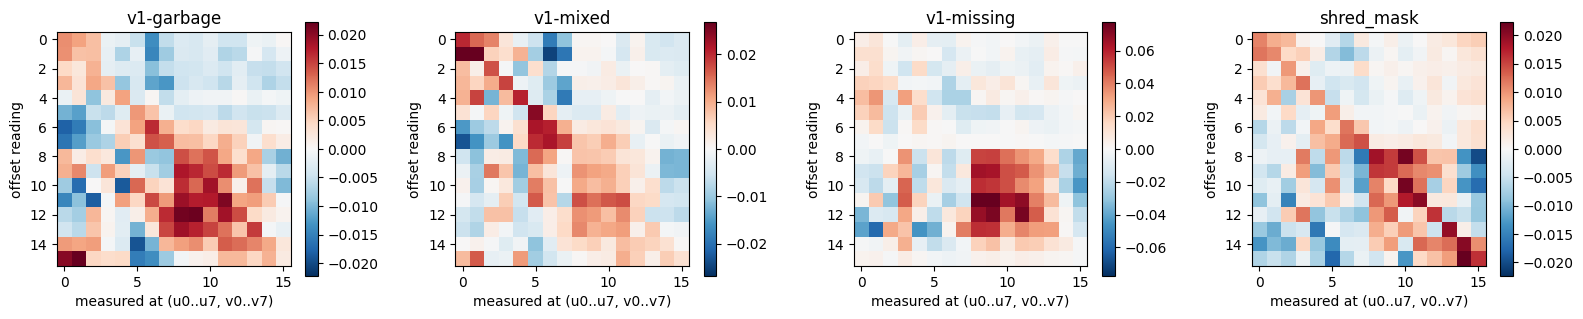

In [3]:
rows = []
fig, axes = plt.subplots(1, len(summary["influence_matrix"]), figsize=(4 * len(summary["influence_matrix"]), 3.6))
for ax, (run, d) in zip(np.atleast_1d(axes), summary["influence_matrix"].items()):
    M = np.array(d["mean_over_seeds"])[0]          # delta = 1 std; (C*N offset, C*N measured)
    n = M.shape[0] // 2
    off = ~np.eye(M.shape[0], dtype=bool)
    same = off & (np.add.outer(np.arange(M.shape[0]) // n, -(np.arange(M.shape[0]) // n)) == 0)
    rows.append([SHORT[run], f"{np.abs(np.diag(M)).mean():.3f}", f"{np.abs(M[same]).mean():.3f}",
                 f"{np.abs(M[off & ~same]).mean():.3f}", f"{np.abs(M[off]).max():.3f}"])
    lim = np.abs(M).max()
    im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set(title=SHORT[run], xlabel="measured at (u0..u7, v0..v7)", ylabel="offset reading")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
display(table(["model", "mean |self|", "mean |other probes, same channel|", "mean |other channel|", "max |off-diag|"],
              rows))

## 2. Reproduction check

The oracle and no-flag variants must reproduce the errors cached by the checkpoints' own experiments
(`random_readings`, and `residual_flags_train` for v1-mixed, whose `garbage_oracle` condition flags every fault):
same checkpoints, draws and device.

In [4]:
rows = []
for variant, flags in [(f"{run}__{fl}", fl) for run in SHORT for fl in ("oracle", "silent")
                       if f"{run}__{fl}" in summary["runs"]]:
    run = variant.rsplit("__", 1)[0]
    source = PROJECT_ROOT / "outputs" / ("residual_flags_train" if "mixed" in run else "random_readings") / "nektar_uv"
    for seed in SEEDS:
        new = json.loads((ROOT / f"seed{seed}" / variant / "result.json").read_text())["metrics"]
        old = json.loads((source / f"seed{seed}" / run / "result.json").read_text())["metrics"]
        diff = max(abs(new[f"garbage_k{k}"]["err"] - old[f"garbage_{flags}_k{k}"]["err"]) for k in KS)
        diff = max(diff, abs(new["clean"]["err"] - old["clean"]["err"]))
        rows.append([LABELS[variant], str(seed), f"{diff:.1e}"])
display(table(["variant", "seed", "max |Δ err| over clean, k = 0..7"], rows))

| variant | seed | max |Δ err| over clean, k = 0..7 |
|---|---|---|
| v1-missing, oracle | 0 | 0.0e+00 |
| v1-missing, oracle | 1 | 0.0e+00 |
| v1-missing, oracle | 2 | 0.0e+00 |
| v1-missing, no flags | 0 | 0.0e+00 |
| v1-missing, no flags | 1 | 0.0e+00 |
| v1-missing, no flags | 2 | 0.0e+00 |
| shred_mask, oracle | 0 | 0.0e+00 |
| shred_mask, oracle | 1 | 0.0e+00 |
| shred_mask, oracle | 2 | 0.0e+00 |
| v1-garbage, oracle | 0 | 0.0e+00 |
| v1-garbage, oracle | 1 | 0.0e+00 |
| v1-garbage, oracle | 2 | 0.0e+00 |
| v1-garbage, no flags (as trained) | 0 | 0.0e+00 |
| v1-garbage, no flags (as trained) | 1 | 0.0e+00 |
| v1-garbage, no flags (as trained) | 2 | 0.0e+00 |
| v1-mixed, oracle | 0 | 0.0e+00 |
| v1-mixed, oracle | 1 | 0.0e+00 |
| v1-mixed, oracle | 2 | 0.0e+00 |
| v1-mixed, no flags | 0 | 0.0e+00 |
| v1-mixed, no flags | 1 | 0.0e+00 |
| v1-mixed, no flags | 2 | 0.0e+00 |

## 3. Field error

`err` by number of garbage probes k (k = 0: noise only, detection on).

| method | clean | k=0 | k=1 | k=2 | k=3 | k=4 | k=7 |
|---|---|---|---|---|---|---|---|
| v1-garbage, oracle | 0.0318 ± 0.0026 | 0.0319 ± 0.0025 | 0.0452 ± 0.0085 | 0.0642 ± 0.0167 | 0.0841 ± 0.0146 | 0.1290 ± 0.0187 | 0.3198 ± 0.0275 |
| v1-garbage, residual q=0.95 | 0.0564 ± 0.0366 | 0.0631 ± 0.0314 | 0.1043 ± 0.0265 | 0.1568 ± 0.0320 | 0.1940 ± 0.0182 | 0.2399 ± 0.0230 | 0.3318 ± 0.0089 |
| v1-garbage, residual q=0.99 | 0.0541 ± 0.0320 | 0.0515 ± 0.0210 | 0.0924 ± 0.0181 | 0.1501 ± 0.0283 | 0.1828 ± 0.0091 | 0.2360 ± 0.0187 | 0.3335 ± 0.0100 |
| v1-garbage, residual q=0.999 | 0.0541 ± 0.0320 | 0.0478 ± 0.0179 | 0.0912 ± 0.0168 | 0.1474 ± 0.0275 | 0.1793 ± 0.0082 | 0.2352 ± 0.0180 | 0.3331 ± 0.0093 |
| v1-garbage, no flags (as trained) | 0.0318 ± 0.0026 | 0.0319 ± 0.0025 | 0.0405 ± 0.0038 | 0.0551 ± 0.0072 | 0.0747 ± 0.0074 | 0.1110 ± 0.0131 | 0.3044 ± 0.0079 |
| v1-garbage, residual soft | 0.0904 ± 0.0320 | 0.0924 ± 0.0279 | 0.1240 ± 0.0191 | 0.1626 ± 0.0220 | 0.1866 ± 0.0053 | 0.2301 ± 0.0112 | 0.3233 ± 0.0072 |
| v1-mixed, oracle | 0.0169 ± 0.0049 | 0.0170 ± 0.0047 | 0.0178 ± 0.0048 | 0.0194 ± 0.0050 | 0.0219 ± 0.0053 | 0.0304 ± 0.0046 | 0.1275 ± 0.0100 |
| v1-mixed, residual q=0.95 | 0.0173 ± 0.0044 | 0.0174 ± 0.0038 | 0.0353 ± 0.0077 | 0.0725 ± 0.0127 | 0.1083 ± 0.0043 | 0.1878 ± 0.0145 | 0.3580 ± 0.0210 |
| v1-mixed, residual q=0.99 | 0.0165 ± 0.0035 | 0.0170 ± 0.0036 | 0.0312 ± 0.0072 | 0.0690 ± 0.0114 | 0.0970 ± 0.0015 | 0.1752 ± 0.0158 | 0.3556 ± 0.0208 |
| v1-mixed, residual q=0.999 | 0.0163 ± 0.0034 | 0.0169 ± 0.0036 | 0.0310 ± 0.0072 | 0.0668 ± 0.0117 | 0.0913 ± 0.0024 | 0.1729 ± 0.0187 | 0.3553 ± 0.0210 |
| v1-mixed, no flags | 0.0169 ± 0.0049 | 0.0170 ± 0.0047 | 0.0220 ± 0.0025 | 0.0301 ± 0.0023 | 0.0387 ± 0.0036 | 0.0678 ± 0.0078 | 0.2925 ± 0.0053 |
| v1-mixed, residual soft | 0.0174 ± 0.0038 | 0.0185 ± 0.0028 | 0.0318 ± 0.0024 | 0.0716 ± 0.0132 | 0.1047 ± 0.0061 | 0.1818 ± 0.0142 | 0.3563 ± 0.0197 |
| v1-mixed, top-k (true k) | 0.0169 ± 0.0049 | 0.0170 ± 0.0047 | 0.0180 ± 0.0044 | 0.0203 ± 0.0051 | 0.0239 ± 0.0052 | 0.0490 ± 0.0148 | 0.3137 ± 0.0095 |
| v1-missing, oracle | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0115 ± 0.0009 | 0.0125 ± 0.0011 | 0.0146 ± 0.0011 | 0.0187 ± 0.0025 | 0.1258 ± 0.0145 |
| v1-missing, residual q=0.95 | 0.0104 ± 0.0010 | 0.0124 ± 0.0011 | 0.1489 ± 0.0194 | 0.2345 ± 0.0359 | 0.2816 ± 0.0384 | 0.3216 ± 0.0425 | 0.3606 ± 0.0479 |
| v1-missing, residual q=0.99 | 0.0105 ± 0.0011 | 0.0120 ± 0.0011 | 0.1333 ± 0.0166 | 0.2225 ± 0.0345 | 0.2705 ± 0.0365 | 0.3162 ± 0.0405 | 0.3585 ± 0.0468 |
| v1-missing, residual q=0.999 | 0.0105 ± 0.0011 | 0.0120 ± 0.0011 | 0.1308 ± 0.0182 | 0.2211 ± 0.0349 | 0.2686 ± 0.0378 | 0.3152 ± 0.0394 | 0.3578 ± 0.0462 |
| v1-missing, no flags | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0715 ± 0.0129 | 0.1231 ± 0.0268 | 0.1687 ± 0.0263 | 0.2153 ± 0.0259 | 0.3415 ± 0.0306 |
| v1-missing, residual soft | 0.0105 ± 0.0014 | 0.0129 ± 0.0017 | 0.1103 ± 0.0124 | 0.1902 ± 0.0363 | 0.2485 ± 0.0275 | 0.2915 ± 0.0287 | 0.3532 ± 0.0440 |
| v1-missing, top-k (true k) | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0562 ± 0.0084 | 0.0948 ± 0.0230 | 0.1478 ± 0.0289 | 0.1873 ± 0.0344 | 0.3491 ± 0.0254 |
| shred_mask, oracle | 0.0099 ± 0.0013 | 0.0102 ± 0.0013 | 0.0446 ± 0.0009 | 0.0804 ± 0.0013 | 0.1385 ± 0.0077 | 0.2114 ± 0.0078 | 0.4568 ± 0.0115 |
| shred_mask, residual q=0.99 | 0.0142 ± 0.0048 | 0.0324 ± 0.0015 | 0.1125 ± 0.0095 | 0.1449 ± 0.0185 | 0.1893 ± 0.0247 | 0.2669 ± 0.0259 | 0.4729 ± 0.0136 |

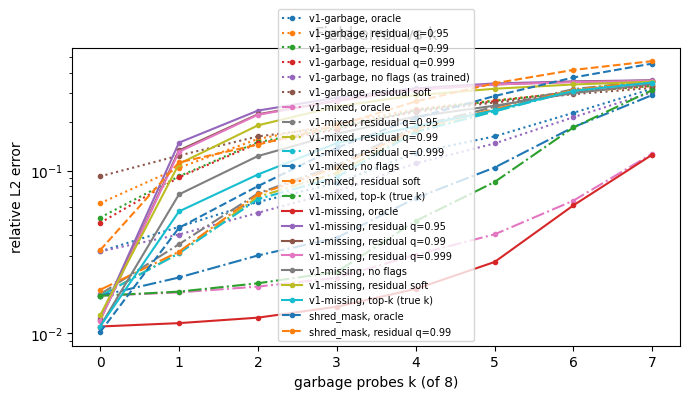

In [5]:
SHOW_K = [0, 1, 2, 3, 4, 7]
rows = [[LABELS[v], fmt(e["clean_err"])] + [fmt(e[f"garbage_k{k}_err"]) for k in SHOW_K]
        for v, e in summary["runs"].items()]
display(table(["method", "clean"] + [f"k={k}" for k in SHOW_K], rows))

fig, ax = plt.subplots(figsize=(7, 4))
for v, e in summary["runs"].items():
    m = np.array([e[f"garbage_k{k}_err"][0] for k in KS])
    style = "--" if v.startswith("shred_mask") else (":" if "__garbage__" in v else ("-." if "mixed" in v else "-"))
    ax.plot(KS, m, style, marker="o", ms=3, label=LABELS[v])
ax.set(xlabel="garbage probes k (of 8)", ylabel="relative L2 error", yscale="log", title="Field error vs k")
ax.legend(fontsize=7)
fig.tight_layout()

## 4. Detection

Per (test window, draw, probe) against the true fault mask. Faults and flags are constant over lags and channels,
so this equals per-reading detection. False-alarm rate = flagged healthy probes / healthy probes. The soft variant
is scored with its q = 0.99 hard flags (`soft_q`).

In [6]:
for key, title in [("recall", "Recall"), ("precision", "Precision"), ("false_alarm", "False-alarm rate")]:
    rows = [[LABELS[v]] + [fmt(e[f"{c}_{key}"], 3) for c in ["clean"] + [f"garbage_k{k}" for k in KS]]
            for v, e in summary["runs"].items() if "oracle" not in v and "silent" not in v]
    display(Markdown(f"**{title}**"))
    display(table(["method", "clean"] + [f"k={k}" for k in KS], rows))

**Recall**

| method | clean | k=0 | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 | k=7 |
|---|---|---|---|---|---|---|---|---|---|
| v1-garbage, residual q=0.95 | – | – | 0.984 ± 0.007 | 0.990 ± 0.002 | 0.985 ± 0.002 | 0.981 ± 0.005 | 0.984 ± 0.003 | 0.983 ± 0.001 | 0.981 ± 0.000 |
| v1-garbage, residual q=0.99 | – | – | 0.977 ± 0.002 | 0.986 ± 0.003 | 0.977 ± 0.005 | 0.973 ± 0.006 | 0.978 ± 0.007 | 0.978 ± 0.004 | 0.972 ± 0.005 |
| v1-garbage, residual q=0.999 | – | – | 0.977 ± 0.002 | 0.983 ± 0.002 | 0.977 ± 0.005 | 0.972 ± 0.006 | 0.976 ± 0.008 | 0.976 ± 0.006 | 0.971 ± 0.006 |
| v1-garbage, residual soft | – | – | 0.977 ± 0.002 | 0.986 ± 0.003 | 0.977 ± 0.005 | 0.973 ± 0.006 | 0.978 ± 0.007 | 0.978 ± 0.004 | 0.972 ± 0.005 |
| v1-mixed, residual q=0.95 | – | – | 0.989 ± 0.011 | 0.996 ± 0.003 | 0.993 ± 0.001 | 0.992 ± 0.002 | 0.994 ± 0.001 | 0.993 ± 0.002 | 0.990 ± 0.003 |
| v1-mixed, residual q=0.99 | – | – | 0.989 ± 0.011 | 0.995 ± 0.004 | 0.992 ± 0.001 | 0.990 ± 0.004 | 0.993 ± 0.001 | 0.992 ± 0.003 | 0.988 ± 0.002 |
| v1-mixed, residual q=0.999 | – | – | 0.988 ± 0.011 | 0.995 ± 0.004 | 0.992 ± 0.001 | 0.989 ± 0.004 | 0.993 ± 0.001 | 0.992 ± 0.004 | 0.988 ± 0.002 |
| v1-mixed, residual soft | – | – | 0.989 ± 0.011 | 0.995 ± 0.004 | 0.992 ± 0.001 | 0.990 ± 0.004 | 0.993 ± 0.001 | 0.992 ± 0.003 | 0.988 ± 0.002 |
| v1-mixed, top-k (true k) | – | – | 0.988 ± 0.009 | 0.982 ± 0.006 | 0.976 ± 0.003 | 0.950 ± 0.017 | 0.928 ± 0.009 | 0.903 ± 0.013 | 0.913 ± 0.005 |
| v1-missing, residual q=0.95 | – | – | 0.995 ± 0.000 | 0.998 ± 0.001 | 0.995 ± 0.001 | 0.993 ± 0.002 | 0.995 ± 0.002 | 0.994 ± 0.001 | 0.996 ± 0.002 |
| v1-missing, residual q=0.99 | – | – | 0.993 ± 0.002 | 0.996 ± 0.001 | 0.994 ± 0.002 | 0.991 ± 0.003 | 0.994 ± 0.001 | 0.992 ± 0.001 | 0.994 ± 0.001 |
| v1-missing, residual q=0.999 | – | – | 0.993 ± 0.002 | 0.996 ± 0.001 | 0.994 ± 0.002 | 0.991 ± 0.004 | 0.994 ± 0.001 | 0.992 ± 0.001 | 0.994 ± 0.000 |
| v1-missing, residual soft | – | – | 0.993 ± 0.002 | 0.996 ± 0.001 | 0.994 ± 0.002 | 0.991 ± 0.003 | 0.994 ± 0.001 | 0.992 ± 0.001 | 0.994 ± 0.001 |
| v1-missing, top-k (true k) | – | – | 0.932 ± 0.011 | 0.868 ± 0.034 | 0.832 ± 0.033 | 0.791 ± 0.024 | 0.800 ± 0.031 | 0.824 ± 0.014 | 0.896 ± 0.004 |
| shred_mask, residual q=0.99 | – | – | 1.000 ± 0.000 | 0.994 ± 0.005 | 0.994 ± 0.004 | 0.993 ± 0.002 | 0.994 ± 0.000 | 0.996 ± 0.002 | 0.993 ± 0.002 |

**Precision**

| method | clean | k=0 | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 | k=7 |
|---|---|---|---|---|---|---|---|---|---|
| v1-garbage, residual q=0.95 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.427 ± 0.046 | 0.509 ± 0.035 | 0.603 ± 0.038 | 0.652 ± 0.018 | 0.720 ± 0.009 | 0.798 ± 0.011 | 0.888 ± 0.005 |
| v1-garbage, residual q=0.99 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.486 ± 0.023 | 0.544 ± 0.033 | 0.636 ± 0.053 | 0.669 ± 0.021 | 0.731 ± 0.009 | 0.804 ± 0.010 | 0.891 ± 0.005 |
| v1-garbage, residual q=0.999 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.495 ± 0.021 | 0.552 ± 0.036 | 0.641 ± 0.057 | 0.672 ± 0.022 | 0.734 ± 0.010 | 0.806 ± 0.011 | 0.891 ± 0.005 |
| v1-garbage, residual soft | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.486 ± 0.023 | 0.544 ± 0.033 | 0.636 ± 0.053 | 0.669 ± 0.021 | 0.731 ± 0.009 | 0.804 ± 0.010 | 0.891 ± 0.005 |
| v1-mixed, residual q=0.95 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.423 ± 0.025 | 0.524 ± 0.019 | 0.595 ± 0.008 | 0.653 ± 0.002 | 0.710 ± 0.014 | 0.790 ± 0.003 | 0.884 ± 0.002 |
| v1-mixed, residual q=0.99 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.477 ± 0.036 | 0.558 ± 0.018 | 0.624 ± 0.006 | 0.669 ± 0.001 | 0.722 ± 0.012 | 0.794 ± 0.003 | 0.885 ± 0.002 |
| v1-mixed, residual q=0.999 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.488 ± 0.039 | 0.566 ± 0.020 | 0.630 ± 0.005 | 0.671 ± 0.001 | 0.724 ± 0.011 | 0.795 ± 0.003 | 0.885 ± 0.001 |
| v1-mixed, residual soft | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.477 ± 0.036 | 0.558 ± 0.018 | 0.624 ± 0.006 | 0.669 ± 0.001 | 0.722 ± 0.012 | 0.794 ± 0.003 | 0.885 ± 0.002 |
| v1-mixed, top-k (true k) | – | – | 0.988 ± 0.009 | 0.982 ± 0.006 | 0.976 ± 0.003 | 0.950 ± 0.017 | 0.928 ± 0.009 | 0.903 ± 0.013 | 0.913 ± 0.005 |
| v1-missing, residual q=0.95 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.227 ± 0.016 | 0.324 ± 0.020 | 0.424 ± 0.019 | 0.527 ± 0.013 | 0.641 ± 0.007 | 0.759 ± 0.005 | 0.877 ± 0.001 |
| v1-missing, residual q=0.99 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.249 ± 0.019 | 0.338 ± 0.024 | 0.434 ± 0.020 | 0.533 ± 0.014 | 0.645 ± 0.010 | 0.761 ± 0.005 | 0.878 ± 0.001 |
| v1-missing, residual q=0.999 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.255 ± 0.021 | 0.340 ± 0.024 | 0.437 ± 0.021 | 0.535 ± 0.013 | 0.645 ± 0.010 | 0.761 ± 0.005 | 0.878 ± 0.001 |
| v1-missing, residual soft | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.249 ± 0.019 | 0.338 ± 0.024 | 0.434 ± 0.020 | 0.533 ± 0.014 | 0.645 ± 0.010 | 0.761 ± 0.005 | 0.878 ± 0.001 |
| v1-missing, top-k (true k) | – | – | 0.932 ± 0.011 | 0.868 ± 0.034 | 0.832 ± 0.033 | 0.791 ± 0.024 | 0.800 ± 0.031 | 0.824 ± 0.014 | 0.896 ± 0.004 |
| shred_mask, residual q=0.99 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.207 ± 0.013 | 0.298 ± 0.005 | 0.403 ± 0.006 | 0.513 ± 0.001 | 0.631 ± 0.002 | 0.753 ± 0.000 | 0.875 ± 0.000 |

**False-alarm rate**

| method | clean | k=0 | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 | k=7 |
|---|---|---|---|---|---|---|---|---|---|
| v1-garbage, residual q=0.95 | 0.077 ± 0.022 | 0.107 ± 0.023 | 0.192 ± 0.035 | 0.322 ± 0.043 | 0.393 ± 0.064 | 0.525 ± 0.039 | 0.638 ± 0.029 | 0.748 ± 0.050 | 0.863 ± 0.045 |
| v1-garbage, residual q=0.99 | 0.055 ± 0.022 | 0.075 ± 0.008 | 0.148 ± 0.014 | 0.277 ± 0.037 | 0.343 ± 0.081 | 0.482 ± 0.048 | 0.599 ± 0.029 | 0.715 ± 0.048 | 0.835 ± 0.039 |
| v1-garbage, residual q=0.999 | 0.055 ± 0.022 | 0.070 ± 0.008 | 0.143 ± 0.012 | 0.268 ± 0.040 | 0.336 ± 0.084 | 0.475 ± 0.050 | 0.589 ± 0.033 | 0.704 ± 0.053 | 0.830 ± 0.041 |
| v1-garbage, residual soft | 0.055 ± 0.022 | 0.075 ± 0.008 | 0.148 ± 0.014 | 0.277 ± 0.037 | 0.343 ± 0.081 | 0.482 ± 0.048 | 0.599 ± 0.029 | 0.715 ± 0.048 | 0.835 ± 0.039 |
| v1-mixed, residual q=0.95 | 0.046 ± 0.016 | 0.118 ± 0.017 | 0.194 ± 0.019 | 0.303 ± 0.023 | 0.406 ± 0.013 | 0.527 ± 0.005 | 0.679 ± 0.047 | 0.792 ± 0.012 | 0.914 ± 0.019 |
| v1-mixed, residual q=0.99 | 0.031 ± 0.016 | 0.087 ± 0.023 | 0.157 ± 0.021 | 0.263 ± 0.020 | 0.360 ± 0.010 | 0.490 ± 0.002 | 0.639 ± 0.038 | 0.773 ± 0.013 | 0.902 ± 0.013 |
| v1-mixed, residual q=0.999 | 0.026 ± 0.019 | 0.082 ± 0.025 | 0.150 ± 0.021 | 0.255 ± 0.020 | 0.350 ± 0.007 | 0.484 ± 0.002 | 0.633 ± 0.036 | 0.767 ± 0.015 | 0.900 ± 0.011 |
| v1-mixed, residual soft | 0.031 ± 0.016 | 0.087 ± 0.023 | 0.157 ± 0.021 | 0.263 ± 0.020 | 0.360 ± 0.010 | 0.490 ± 0.002 | 0.639 ± 0.038 | 0.773 ± 0.013 | 0.902 ± 0.013 |
| v1-mixed, top-k (true k) | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.002 ± 0.001 | 0.006 ± 0.002 | 0.014 ± 0.002 | 0.050 ± 0.017 | 0.120 ± 0.014 | 0.291 ± 0.040 | 0.607 ± 0.035 |
| v1-missing, residual q=0.95 | 0.031 ± 0.025 | 0.139 ± 0.021 | 0.487 ± 0.042 | 0.697 ± 0.062 | 0.813 ± 0.062 | 0.892 ± 0.045 | 0.930 ± 0.029 | 0.949 ± 0.028 | 0.975 ± 0.007 |
| v1-missing, residual q=0.99 | 0.015 ± 0.008 | 0.093 ± 0.018 | 0.432 ± 0.042 | 0.656 ± 0.068 | 0.781 ± 0.063 | 0.869 ± 0.048 | 0.913 ± 0.039 | 0.937 ± 0.027 | 0.970 ± 0.007 |
| v1-missing, residual q=0.999 | 0.013 ± 0.005 | 0.087 ± 0.017 | 0.419 ± 0.044 | 0.651 ± 0.067 | 0.773 ± 0.066 | 0.862 ± 0.047 | 0.911 ± 0.040 | 0.933 ± 0.029 | 0.968 ± 0.009 |
| v1-missing, residual soft | 0.015 ± 0.008 | 0.093 ± 0.018 | 0.432 ± 0.042 | 0.656 ± 0.068 | 0.781 ± 0.063 | 0.869 ± 0.048 | 0.913 ± 0.039 | 0.937 ± 0.027 | 0.970 ± 0.007 |
| v1-missing, top-k (true k) | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.010 ± 0.002 | 0.044 ± 0.011 | 0.101 ± 0.020 | 0.209 ± 0.024 | 0.333 ± 0.051 | 0.529 ± 0.042 | 0.725 ± 0.026 |
| shred_mask, residual q=0.99 | 0.004 ± 0.003 | 0.079 ± 0.011 | 0.549 ± 0.045 | 0.780 ± 0.021 | 0.885 ± 0.018 | 0.944 ± 0.003 | 0.970 ± 0.007 | 0.981 ± 0.002 | 0.989 ± 0.004 |

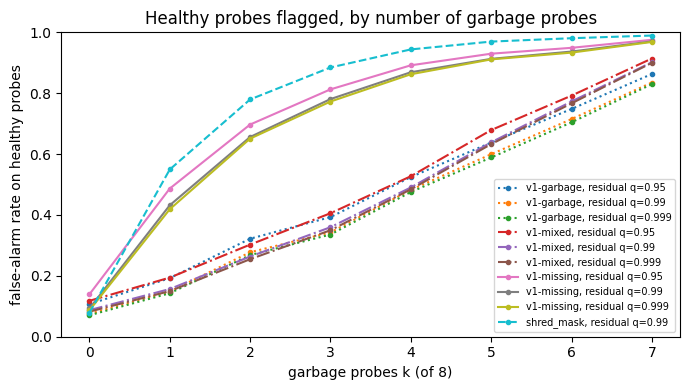

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for v, e in summary["runs"].items():
    if "residual" not in v:
        continue
    fa = [e[f"garbage_k{k}_false_alarm"][0] for k in KS]
    ax.plot(KS, fa, "--" if v.startswith("shred_mask") else (":" if "__garbage__" in v else ("-." if "mixed" in v else "-")), marker="o", ms=3, label=LABELS[v])
ax.set(xlabel="garbage probes k (of 8)", ylabel="false-alarm rate on healthy probes", ylim=(0, 1),
       title="Healthy probes flagged, by number of garbage probes")
ax.legend(fontsize=7)
fig.tight_layout()

## 5. Error vs q (v1, residual flags)

Field error at k = 2 against the threshold quantile q, with v1 oracle (upper bound) and no flags (lower bound) as
references.

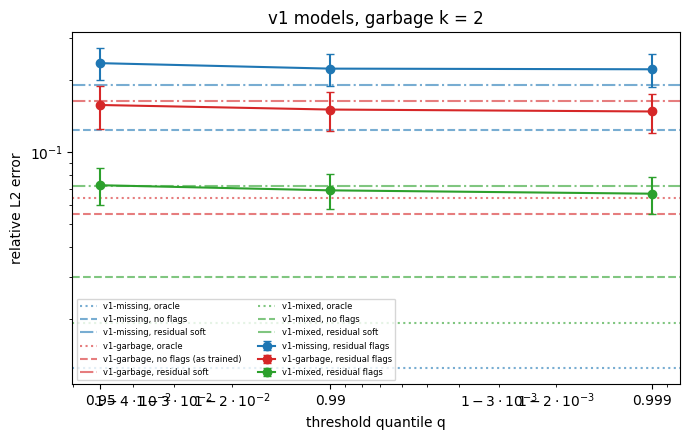

In [8]:
K = 2
qs = [0.95, 0.99, 0.999]
runs = summary["runs"]
fig, ax = plt.subplots(figsize=(7, 4.5))
for run, color in [("robust_shred_v1__missing", "C0"), ("robust_shred_v1__garbage", "C3"),
                   ("robust_shred_v1__garbage_mixed", "C2")]:
    m = np.array([runs[f"{run}__residual_q{q:g}"][f"garbage_k{K}_err"] for q in qs])
    ax.errorbar(qs, m[:, 0], yerr=m[:, 1], marker="o", capsize=3, color=color,
                label=LABELS[f"{run}__residual_q0.99"].replace(" q=0.99", " flags"))
    for flags, ls in [("oracle", ":"), ("silent", "--"), ("soft", "-.")]:
        ax.axhline(runs[f"{run}__{flags}"][f"garbage_k{K}_err"][0], ls=ls, color=color, alpha=0.6,
                   label=LABELS[f"{run}__{flags}"])
ax.set(xscale="logit", xticks=qs, xticklabels=[str(q) for q in qs], xlabel="threshold quantile q",
       ylabel="relative L2 error", yscale="log", title=f"v1 models, garbage k = {K}")
ax.legend(fontsize=6, ncol=2)
fig.tight_layout()

## 7. Does the score separate faulty from healthy probes?

The fixed threshold might hide a usable score. Pass-1 scores d_j (independent of q) and true labels per (window,
draw, probe), saved by the residual q = 0.99 variants (`arrays.npz`), for v1-missing, v1-mixed and shred_mask.
All numbers are mean ± std over seeds, each seed computed on its own 190 cases per k (19 test windows × 10 draws).

- **Rank accuracy:** fraction of cases where the k faulty probes are exactly the k highest scores.
- **Score gap:** median score of the faulty probes / 95th percentile of the healthy-probe scores, pooled over the
  cases with k faults (> 1: most faulty probes score above nearly all healthy ones).

In [9]:
from get_shredded.residual_flags import top_k_flags

SCORE_RUNS = {"v1-missing": "robust_shred_v1__missing", "v1-mixed": "robust_shred_v1__garbage_mixed",
              "shred_mask": "shred_mask__missing"}

def arrays(run, seed):
    with np.load(ROOT / f"seed{seed}" / f"{run}__residual_q0.99" / "arrays.npz") as z:
        return {k: z[k] for k in z.files}

A = {(name, seed): arrays(run, seed) for name, run in SCORE_RUNS.items() for seed in SEEDS}

def per_seed(fn, name, k):
    return [fn(A[(name, seed)], k) for seed in SEEDS]

def rank_acc(a, k):
    d, t = a[f"garbage_k{k}_score"], a[f"garbage_k{k}_truth"]
    return float((top_k_flags(d, t.sum(1)) == t).all(1).mean())

def gap(a, k):
    d, t = a[f"garbage_k{k}_score"], a[f"garbage_k{k}_truth"]
    return float(np.median(d[t]) / np.percentile(d[~t], 95))

def ms(vals, digits=3):
    return f"{np.mean(vals):.{digits}f} ± {np.std(vals):.{digits}f}"

for title, fn in [("Rank accuracy", rank_acc), ("Score gap (median faulty / p95 healthy)", gap)]:
    display(Markdown(f"**{title}**"))
    display(table(["model"] + [f"k={k}" for k in range(1, 8)],
                  [[name] + [ms(per_seed(fn, name, k)) for k in range(1, 8)] for name in SCORE_RUNS]))

**Rank accuracy**

| model | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 | k=7 |
|---|---|---|---|---|---|---|---|
| v1-missing | 0.932 ± 0.011 | 0.768 ± 0.045 | 0.614 ± 0.044 | 0.421 ± 0.035 | 0.346 ± 0.053 | 0.258 ± 0.039 | 0.275 ± 0.026 |
| v1-mixed | 0.988 ± 0.009 | 0.963 ± 0.011 | 0.932 ± 0.004 | 0.825 ± 0.062 | 0.693 ± 0.047 | 0.533 ± 0.056 | 0.393 ± 0.035 |
| shred_mask | 0.972 ± 0.011 | 0.889 ± 0.030 | 0.718 ± 0.033 | 0.475 ± 0.017 | 0.321 ± 0.042 | 0.228 ± 0.007 | 0.214 ± 0.017 |

**Score gap (median faulty / p95 healthy)**

| model | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 | k=7 |
|---|---|---|---|---|---|---|---|
| v1-missing | 2.234 ± 0.500 | 1.413 ± 0.296 | 1.045 ± 0.138 | 0.868 ± 0.089 | 0.781 ± 0.071 | 0.701 ± 0.051 | 0.638 ± 0.041 |
| v1-mixed | 6.798 ± 0.123 | 4.924 ± 0.279 | 3.997 ± 0.369 | 2.559 ± 0.515 | 1.648 ± 0.256 | 1.003 ± 0.124 | 0.651 ± 0.011 |
| shred_mask | 4.270 ± 0.440 | 2.645 ± 0.120 | 1.736 ± 0.129 | 1.305 ± 0.053 | 1.041 ± 0.045 | 0.809 ± 0.027 | 0.741 ± 0.010 |

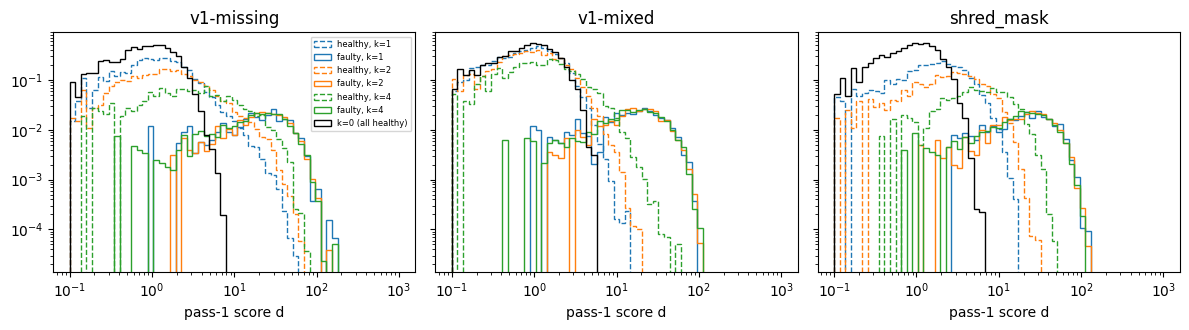

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, name in zip(axes, SCORE_RUNS):
    for k, color in [(1, "C0"), (2, "C1"), (4, "C2")]:
        d = np.concatenate([A[(name, s)][f"garbage_k{k}_score"].ravel() for s in SEEDS])
        t = np.concatenate([A[(name, s)][f"garbage_k{k}_truth"].ravel() for s in SEEDS])
        bins = np.logspace(-1, 3, 60)
        ax.hist(d[~t], bins, histtype="step", color=color, ls="--", density=True, label=f"healthy, k={k}")
        ax.hist(d[t], bins, histtype="step", color=color, density=True, label=f"faulty, k={k}")
    d0 = np.concatenate([A[(name, s)]["garbage_k0_score"].ravel() for s in SEEDS])
    ax.hist(d0, bins, histtype="step", color="k", density=True, label="k=0 (all healthy)")
    ax.set(xscale="log", yscale="log", title=name, xlabel="pass-1 score d")
axes[0].legend(fontsize=6)
fig.tight_layout()

### Flags per window at q = 0.99

Share of cases with a given number of flagged probes, and the mean per-snapshot relative error of those cases
(pass 2 with those flags). Per-snapshot errors average differently from the pooled `err` above, so compare
within this table.

In [11]:
for k in (1, 2):
    rows = []
    for name in SCORE_RUNS:
        share = np.zeros((len(SEEDS), 9))
        err = np.full((len(SEEDS), 9), np.nan)
        for i, seed in enumerate(SEEDS):
            a = A[(name, seed)]
            n_flag = a[f"garbage_k{k}_flags"].sum(1)
            for c in range(9):
                sel = n_flag == c
                share[i, c] = sel.mean()
                if sel.any():
                    err[i, c] = a[f"garbage_k{k}_err"][sel].mean()
        used = [c for c in range(9) if share[:, c].max() > 0]
        rows.append([name, "share"] + [f"{share[:, c].mean():.2f}" if c in used else "–" for c in range(9)])
        rows.append(["", "error"] + [f"{np.nanmean(err[:, c]):.3f}" if c in used else "–" for c in range(9)])
    display(Markdown(f"**k = {k} faulty probes**"))
    display(table(["model", ""] + [f"{c} flagged" for c in range(9)], rows))

**k = 1 faulty probes**

| model |  | 0 flagged | 1 flagged | 2 flagged | 3 flagged | 4 flagged | 5 flagged | 6 flagged | 7 flagged | 8 flagged |
|---|---|---|---|---|---|---|---|---|---|---|
| v1-missing | share | 0.00 | 0.22 | 0.18 | 0.11 | 0.06 | 0.06 | 0.11 | 0.14 | 0.11 |
|  | error | 0.010 | 0.010 | 0.012 | 0.017 | 0.022 | 0.024 | 0.052 | 0.070 | 0.367 |
| v1-mixed | share | 0.01 | 0.41 | 0.30 | 0.16 | 0.07 | 0.03 | 0.02 | 0.00 | 0.00 |
|  | error | 0.022 | 0.016 | 0.017 | 0.023 | 0.023 | 0.043 | 0.064 | 0.242 | 0.354 |
| shred_mask | share | – | 0.06 | 0.10 | 0.11 | 0.15 | 0.16 | 0.17 | 0.19 | 0.07 |
|  | error | – | 0.044 | 0.054 | 0.070 | 0.092 | 0.110 | 0.122 | 0.142 | 0.143 |

**k = 2 faulty probes**

| model |  | 0 flagged | 1 flagged | 2 flagged | 3 flagged | 4 flagged | 5 flagged | 6 flagged | 7 flagged | 8 flagged |
|---|---|---|---|---|---|---|---|---|---|---|
| v1-missing | share | – | 0.00 | 0.08 | 0.10 | 0.11 | 0.05 | 0.12 | 0.21 | 0.32 |
|  | error | – | 0.016 | 0.010 | 0.013 | 0.020 | 0.030 | 0.061 | 0.078 | 0.363 |
| v1-mixed | share | – | 0.00 | 0.31 | 0.28 | 0.16 | 0.11 | 0.08 | 0.04 | 0.02 |
|  | error | – | 0.014 | 0.016 | 0.019 | 0.029 | 0.039 | 0.053 | 0.094 | 0.402 |
| shred_mask | share | – | – | 0.01 | 0.02 | 0.04 | 0.09 | 0.19 | 0.32 | 0.31 |
|  | error | – | – | 0.069 | 0.108 | 0.098 | 0.110 | 0.116 | 0.145 | 0.161 |

### Top-k flags

Flag the k highest-scoring probes, with k = the true number of faults (an upper bound for any rule that ranks the
probes), then pass 2 as for residual flags.

In [12]:
rows = []
for v in ["robust_shred_v1__missing__oracle", "robust_shred_v1__missing__topk", "robust_shred_v1__missing__silent",
          "robust_shred_v1__garbage_mixed__oracle", "robust_shred_v1__garbage_mixed__topk",
          "robust_shred_v1__garbage_mixed__silent", "robust_shred_v1__garbage_mixed__residual_q0.99"]:
    e = summary["runs"][v]
    rows.append([LABELS[v]] + [fmt(e[f"garbage_k{k}_err"]) for k in (0, 1, 2, 3, 4, 7)])
display(table(["method"] + [f"k={k}" for k in (0, 1, 2, 3, 4, 7)], rows))

| method | k=0 | k=1 | k=2 | k=3 | k=4 | k=7 |
|---|---|---|---|---|---|---|
| v1-missing, oracle | 0.0110 ± 0.0008 | 0.0115 ± 0.0009 | 0.0125 ± 0.0011 | 0.0146 ± 0.0011 | 0.0187 ± 0.0025 | 0.1258 ± 0.0145 |
| v1-missing, top-k (true k) | 0.0110 ± 0.0008 | 0.0562 ± 0.0084 | 0.0948 ± 0.0230 | 0.1478 ± 0.0289 | 0.1873 ± 0.0344 | 0.3491 ± 0.0254 |
| v1-missing, no flags | 0.0110 ± 0.0008 | 0.0715 ± 0.0129 | 0.1231 ± 0.0268 | 0.1687 ± 0.0263 | 0.2153 ± 0.0259 | 0.3415 ± 0.0306 |
| v1-mixed, oracle | 0.0170 ± 0.0047 | 0.0178 ± 0.0048 | 0.0194 ± 0.0050 | 0.0219 ± 0.0053 | 0.0304 ± 0.0046 | 0.1275 ± 0.0100 |
| v1-mixed, top-k (true k) | 0.0170 ± 0.0047 | 0.0180 ± 0.0044 | 0.0203 ± 0.0051 | 0.0239 ± 0.0052 | 0.0490 ± 0.0148 | 0.3137 ± 0.0095 |
| v1-mixed, no flags | 0.0170 ± 0.0047 | 0.0220 ± 0.0025 | 0.0301 ± 0.0023 | 0.0387 ± 0.0036 | 0.0678 ± 0.0078 | 0.2925 ± 0.0053 |
| v1-mixed, residual q=0.99 | 0.0170 ± 0.0036 | 0.0312 ± 0.0072 | 0.0690 ± 0.0114 | 0.0970 ± 0.0015 | 0.1752 ± 0.0158 | 0.3556 ± 0.0208 |

## 8. Notes

Conclusion (agreed with the user, tentative): `experiments/residual_flags/README.md`, section *Conclusion*.
Fixed-threshold residual flags are worse than no flags, because garbage lifts the healthy probes' scores and every
false alarm removes a healthy probe. Correct flags still help (oracle, top-k), and the score ranks faulty probes
well. Soft weights act as an attention intervention, close to hard exclusion. Best without an oracle: v1-mixed
with no flags.